# 04 RNN人名分类器搭建、训练与预测

本篇对应 **day04**，保存在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。承接03的字符编码、变长批次和循环网络，本篇把它们组合成一个可训练、可验证、可保存、可预测的人名分类器，并用同一接口比较RNN、LSTM和GRU。

资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。已核对 `03-视频/day04` 的 **11节标题**，在线阅读《05-RNN案例人名分类器》全部47页；本篇重点对应第18–47页的模型构建、训练与预测。视频未逐段转录，未取得课程原代码、原始人名文件和本地PDF。

本篇讲解、代码、72条教学样本和7幅图独立编写。**课件实验观察与本篇CPU小样本实验分开标注**，不把教学样本当作课程语料，也不把模型类别当作某个人的真实国籍。沿用前篇格式：全部为Markdown单元，Python代码块按顺序复制到代码单元即可运行；图片全部嵌入Notebook附件，无需其他图片文件。

| day04视频 | 内容 | 本篇对应 |
| --- | --- | --- |
| 01 | LogSoftmax函数 | 稳定计算、对数概率与NLLLoss |
| 02–03 | 搭建、测试RNN模型 | 单条接口、逐字符与整段前向 |
| 04–05 | 搭建、测试LSTM和GRU | 状态差异、统一分类器、shape检查 |
| 06–08 | 三种模型训练 | 训练循环、梯度、损失、验证集 |
| 09 | 三种模型可视化 | 真实训练曲线、验证指标与耗时 |
| 10–11 | 预测、思路总结 | Top-k、保存加载、完整流程复盘 |

读完应能独立完成：`name → one-hot → packed RNN → 分类头 → LogSoftmax → NLLLoss → 优化器`，并说明为什么右padding、隐藏状态、类别顺序、验证划分和保存配置会影响最终结果。

## 1. 环境与运行方式

只需要Python、NumPy和PyTorch；本篇代码不联网、不依赖课程数据。图已经内嵌，阅读无需安装绘图库。默认CPU，全部Python代码块按笔记顺序在同一个会话执行。

```bash
python -m pip install numpy torch
```

```python
import copy
import json
import math
import platform
import string
import tempfile
import time
import unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import Dataset, DataLoader

SEED = 2026
DEVICE = torch.device("cpu")
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
print("Python", platform.python_version(), "NumPy", np.__version__)
print("PyTorch", torch.__version__, "device", DEVICE)
```

固定种子便于核对；不同版本、设备、线程数可能产生数值和耗时差异。模型文件示例使用自动清理的系统临时目录，不在笔记文件夹留下权重或数据。

## 2. 任务：一个名字对应一个类别

课件的任务是**序列分类**：读完整个人名后，输出18类中的一个类别。不是每个字符分类，也不是生成下一个字符。课件称原数据有20074条、18类；这是课件说明，本篇未核验原文件。

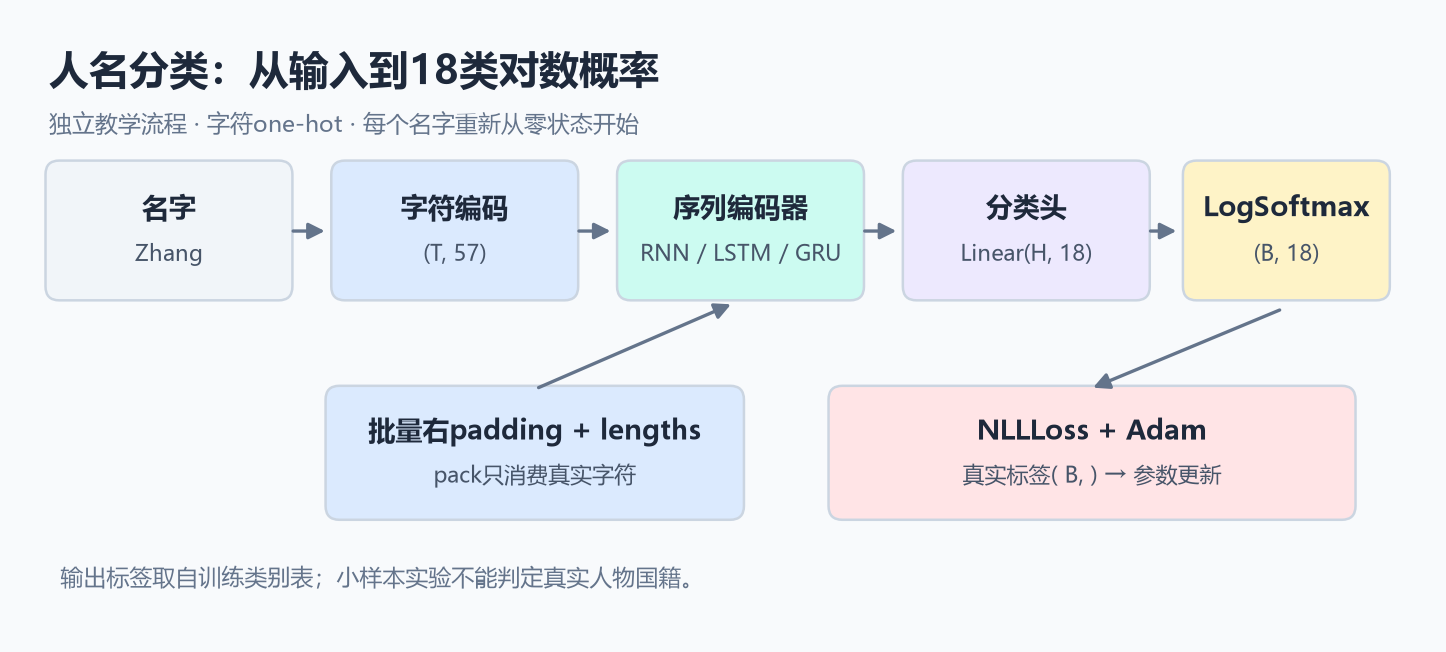

字符编码维度 `I=57`；隐藏维度 `H` 是模型超参数；输出维度 `C=18`。本篇保留课件类别顺序，教学数据只包含其中3类。因此模型仍输出18个数，其余15类没有正样本，**不能据此评估完整18类任务**。

人名可能被多种语言共同使用，拼写、转写和标签来源也有歧义。这里的输出表示“模型对训练标签的分数”，不能用于确定身份、民族或国籍。

## 3. LogSoftmax输出的是对数概率

分类头给出原始分数（logits）$z\in\mathbb{R}^{C}$。Softmax和LogSoftmax分别是：

$$p_i=\frac{e^{z_i}}{\sum_j e^{z_j}},\qquad \ell_i=\log p_i=z_i-\log\sum_j e^{z_j}.$$

`LogSoftmax`返回$\ell$，**不是$p$**。有限输入下对数概率不大于0；`log_probs.exp()`才是概率，各类别概率和约为1。`argmax(logits)`、`argmax(log_probs)`、`argmax(probs)`相同，因为这些变换保持排序。

不要先直接计算大数的指数。令$m=\max_j z_j$，稳定形式为：

$$\ell_i=(z_i-m)-\log\sum_j e^{z_j-m}.$$

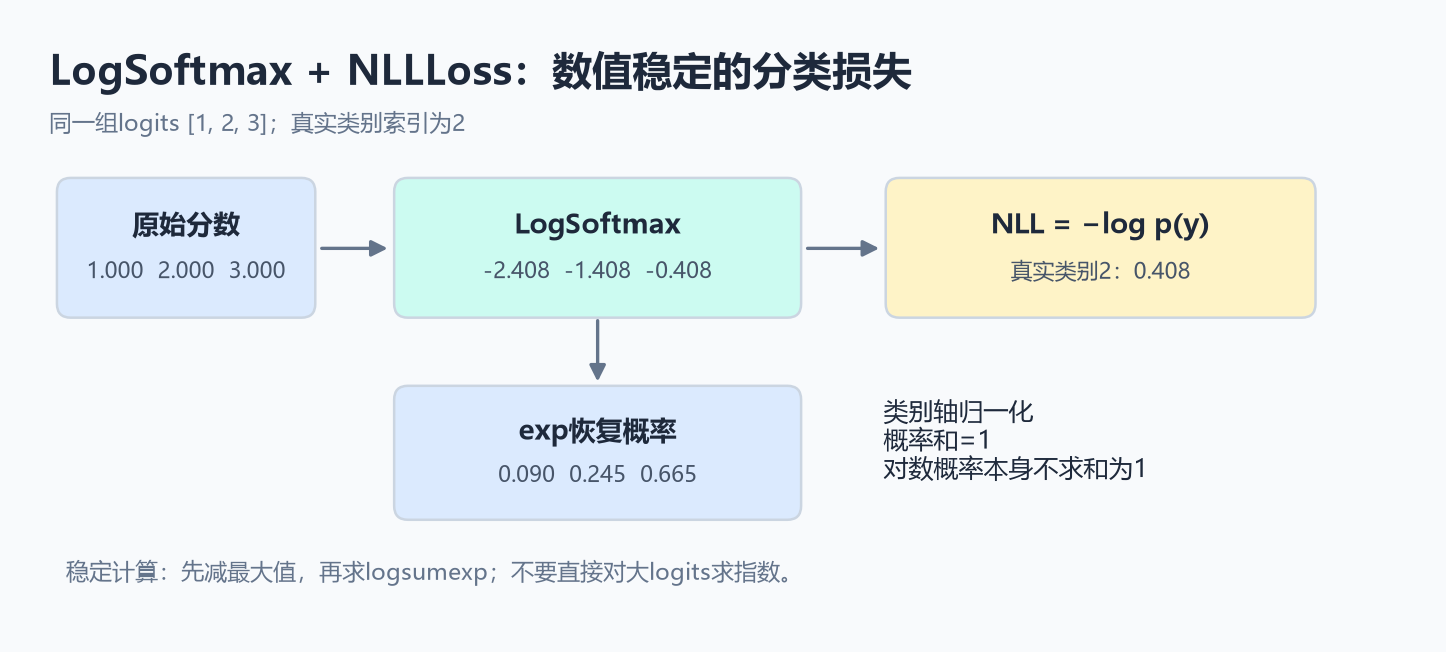

```python
def stable_log_softmax(z):
    shifted = z - z.max(dim=-1, keepdim=True).values
    return shifted - shifted.exp().sum(dim=-1, keepdim=True).log()

z = torch.tensor([[1.0, 2.0, 3.0], [1000.0, 1001.0, 1002.0]], dtype=torch.float64)
log_probs = nn.LogSoftmax(dim=-1)(z)
torch.testing.assert_close(log_probs, stable_log_softmax(z))
torch.testing.assert_close(log_probs[0], log_probs[1])
torch.testing.assert_close(log_probs.exp().sum(-1), torch.ones(2, dtype=torch.float64))
assert torch.isfinite(log_probs).all()
assert torch.equal(z.argmax(-1), log_probs.argmax(-1))
print("log_probs:\n", log_probs)
print("probs:\n", log_probs.exp())
```

`dim=-1`在这里表示类别轴。对形状`(B,C)`沿`dim=0`归一化，会在不同样本之间竞争，任务含义就错了。

## 4. NLLLoss与CrossEntropyLoss怎样配对

一个样本真实类别为$y$，负对数似然损失为$-\ell_y$；默认平均损失：

$$L=-\frac1B\sum_{b=1}^{B}\ell_{b,y_b}.$$

| 输出 | 损失函数 | 推荐用法 |
| --- | --- | --- |
| logits `(B,C)` | `CrossEntropyLoss` | 内部完成LogSoftmax和NLL |
| log_probs `(B,C)` | `NLLLoss` | 与课件分类器对应 |
| probs `(B,C)` | 上述两者均不要直接这样搭配 | CE会把概率误当logits；NLL会误把概率当对数概率 |

**标签是类别索引**，shape `(B,)`、dtype `torch.long`，不是字符one-hot，也不是类别字符串。本篇统一用`LogSoftmax + NLLLoss`。若选择CE，应让分类器直接返回logits。对已规范化log_probs再用CE在数学上可等价，但重复归一化多余且混淆接口。

```python
raw = torch.tensor([[1.0, 2.0, -1.0], [0.5, -0.5, 1.5]],
                   dtype=torch.float64, requires_grad=True)
targets = torch.tensor([1, 2], dtype=torch.long)
lp = raw.log_softmax(-1)
nll = nn.NLLLoss()(lp, targets)
ce = nn.CrossEntropyLoss()(raw, targets)
manual = -lp[torch.arange(len(targets)), targets].mean()
torch.testing.assert_close(nll, ce)
torch.testing.assert_close(nll, manual)
g_nll = torch.autograd.grad(nll, raw, retain_graph=True)[0]
g_ce = torch.autograd.grad(ce, raw)[0]
torch.testing.assert_close(g_nll, g_ce)
print("NLL = CE =", nll.item(), "梯度也一致")
```

## 5. 重申第03篇的数据契约

为使本篇可以独立运行，重新定义字符表、类别顺序和编码。预处理规则与03一致：去首尾空白、NFD分解后去掉重音标记，保留大小写；剩余未知字符或空名字直接报错。

```python
ALL_LETTERS = string.ascii_letters + " .,;'"
CATEGORIES = [
    "Italian", "English", "Arabic", "Spanish", "Scottish", "Irish",
    "Chinese", "Vietnamese", "Japanese", "French", "Greek", "Dutch",
    "Korean", "Polish", "Portuguese", "Russian", "Czech", "German",
]
LETTER_TO_ID = {ch: i for i, ch in enumerate(ALL_LETTERS)}
CATEGORY_TO_ID = {name: i for i, name in enumerate(CATEGORIES)}
PREPROCESS = "strip+nfd_drop_Mn+case_sensitive+reject_unknown_and_empty:v1"
assert len(ALL_LETTERS) == 57 and len(CATEGORIES) == 18

def normalize_name(name):
    if not isinstance(name, str):
        raise TypeError("name必须是字符串")
    name = "".join(ch for ch in unicodedata.normalize("NFD", name.strip())
                   if unicodedata.category(ch) != "Mn")
    if not name or any(ch not in LETTER_TO_ID for ch in name):
        raise ValueError("名字为空或含字符表以外的字符")
    return name

def name_to_tensor(name):
    name = normalize_name(name)
    ids = torch.tensor([LETTER_TO_ID[ch] for ch in name], dtype=torch.long)
    return torch.nn.functional.one_hot(ids, len(ALL_LETTERS)).float()

assert normalize_name("  José  ") == "Jose"
assert normalize_name("Zhang") != normalize_name("zhang")
assert name_to_tensor("Li").shape == (2, 57)
assert name_to_tensor("a")[0, 0].item() == 1
for bad_name in ("", "   ", "张三", "A🙂", "123"):
    try:
        name_to_tensor(bad_name)
    except ValueError:
        pass
    else:
        raise AssertionError("未知字符或空名应被拒绝")
print("字符数", len(ALL_LETTERS), "类别数", len(CATEGORIES))
```

去重音是一种**有损规范化**，例如`José`和`Jose`变得相同。未知字符不能用`str.find()`返回的`-1`直接索引，否则会偷偷写入最后一列。第0列对应`a`，**不是PAD**；本篇PAD是57维全零行。

## 6. 从课件的单条接口搭建三种模型

课件单条输入是`(T,57)`，补一个batch维度变成`(T,1,57)`，编码器输出最后一个时间步，再接`Linear(H,18)`与`LogSoftmax`。这里用一个类统一三种结构，隐藏状态作为显式参数便于测试。

```python
class SingleNameClassifier(nn.Module):
    def __init__(self, kind="RNN", hidden_size=128, num_layers=1):
        super().__init__()
        if kind not in {"RNN", "LSTM", "GRU"}:
            raise ValueError("kind必须为RNN、LSTM或GRU")
        self.kind = kind
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.encoder = getattr(nn, kind)(57, hidden_size, num_layers=num_layers)
        self.head = nn.Linear(hidden_size, 18)
        self.log_softmax = nn.LogSoftmax(dim=-1)

    def initial_state(self):
        parameter = next(self.parameters())
        shape = (self.num_layers, 1, self.hidden_size)
        h0 = parameter.new_zeros(shape)
        if self.kind == "LSTM":
            return h0, parameter.new_zeros(shape)
        return h0

    def forward(self, sequence, state=None):
        if sequence.ndim != 2 or sequence.shape[1] != 57 or len(sequence) == 0:
            raise ValueError("单条输入必须为非空(T,57)")
        if state is None:
            state = self.initial_state()
        output, state = self.encoder(sequence.unsqueeze(1), state)
        logits = self.head(output[-1])
        return self.log_softmax(logits), state
```

| 网络 | 输入状态 | 返回状态 | 状态shape |
| --- | --- | --- | --- |
| RNN | `h0` | `hn` | `(L,1,H)` |
| GRU | `h0` | `hn` | `(L,1,H)` |
| LSTM | `(h0,c0)` | `(hn,cn)` | 两个张量都是`(L,1,H)` |

LSTM的`c`负责细胞记忆，不直接接分类头。本接口只支持**单向、无dropout**的模型，便于与课件逐字符计算对照。

## 7. 测试：整段输入与逐字符输入一致

整段调用内部已经沿时间递推，不需要外部再循环一次。逐字符写法则必须把同一名字上一字符的状态传给下一字符；最终分类输出应与整段调用一致。

```python
def state_tensors(state):
    return state if isinstance(state, tuple) else (state,)

single_checks = {}
for kind in ("RNN", "LSTM", "GRU"):
    torch.manual_seed(SEED)
    model = SingleNameClassifier(kind, hidden_size=16, num_layers=2).double().eval()
    sequence = name_to_tensor("Zhang").double()
    with torch.inference_mode():
        whole, whole_state = model(sequence)
        state = model.initial_state()
        for ch in sequence:
            step, state = model(ch.unsqueeze(0), state)
        torch.testing.assert_close(whole, step, atol=1e-10, rtol=1e-10)
        for a, b in zip(state_tensors(whole_state), state_tensors(state)):
            torch.testing.assert_close(a, b, atol=1e-10, rtol=1e-10)
        # 先读其他名字后，再以默认零状态读Zhang，结果不变。
        model(name_to_tensor("Smith").double())
        repeat, _ = model(sequence)
        torch.testing.assert_close(whole, repeat)
    assert whole.shape == (1, 18)
    single_checks[kind] = (whole - step).abs().max().item()
print("整段/逐字符最大误差:", single_checks)
```

这里证明接口与状态传递正确，**随机模型没有学会分类**。如果在每个字符处重新置零，模型只能看到最后一个字符；如果把上一名字的状态带入下一名字，独立样本会彼此污染。双向网络、训练态dropout等条件也不能直接套用这个等价检查。

## 8. 批量输入：不要取padding之后的最后一步

单条无padding时，`output[-1]`是有效序列末尾；批量右padding时，短名字的张量最后位置是PAD。即使输入全零，循环网络的偏置和状态递推仍会改变隐藏状态，因此不能用`padded_output[:, -1]`代表每个名字。

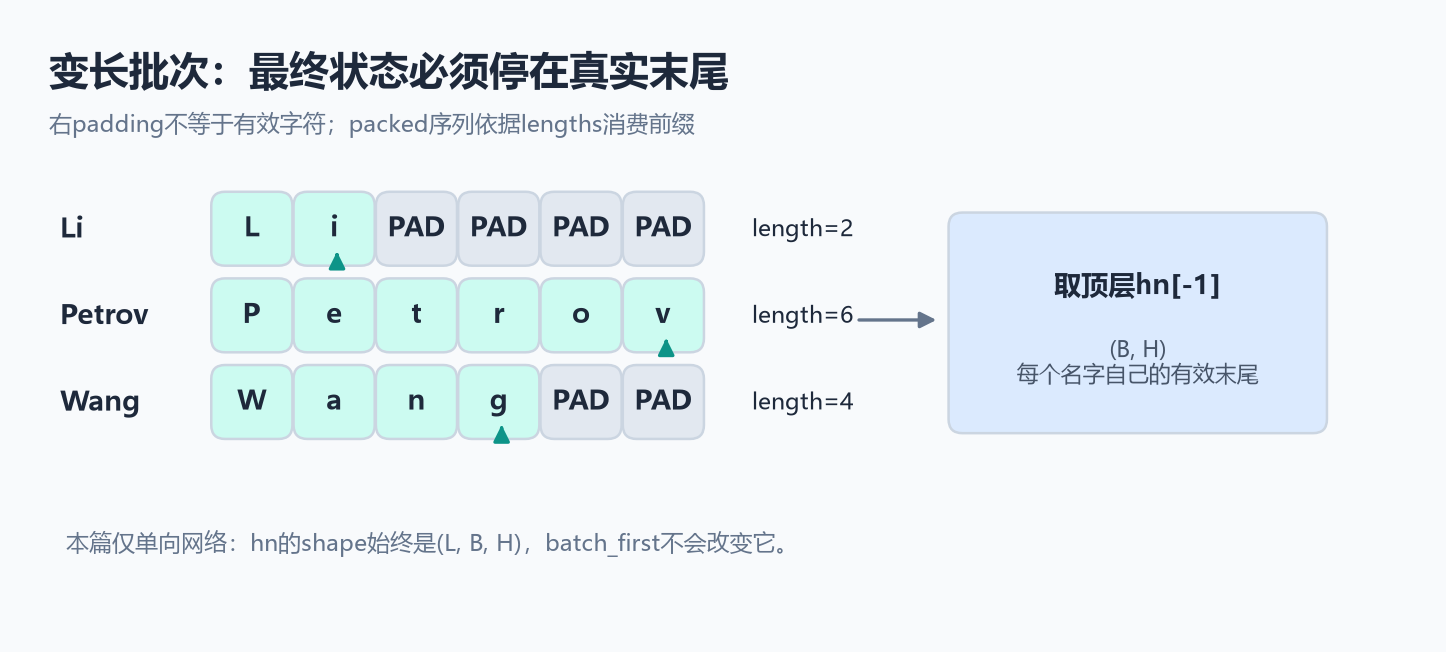

本篇采用`pack_padded_sequence`：传入真实长度，编码器跳过右侧PAD；返回的`hn`是每个样本有效末尾的状态。`enforce_sorted=False`允许批次未按长度排序，PyTorch返回的状态会恢复到原批次顺序。单向模型顶层表示是`hn[-1]`，shape `(B,H)`。

`batch_first=True`只改变输入/输出的batch维位置，**不改变隐藏状态shape**：仍是`(L,B,H)`。双向时第一维变成`L*2`，不能只取一个方向的`hn[-1]`；双向完整处理留待相应任务。

## 9. 通用packed批量分类器

训练模型使用统一签名：`model(x, lengths) → (B,18)`。`x`为右补齐的float32 one-hot `(B,T,57)`，`lengths`为CPU上的long `(B,)`且每项在`[1,T]`。padding检查由数据接口负责，模型不猜测真实长度。

```python
class PackedNameClassifier(nn.Module):
    def __init__(self, kind="RNN", input_size=57, hidden_size=32,
                 num_layers=1, num_classes=18):
        super().__init__()
        if kind not in {"RNN", "LSTM", "GRU"}:
            raise ValueError("不支持的网络类型")
        self.config = dict(kind=kind, input_size=input_size, hidden_size=hidden_size,
                           num_layers=num_layers, num_classes=num_classes)
        self.encoder = getattr(nn, kind)(input_size, hidden_size,
                                        num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)
        self.log_softmax = nn.LogSoftmax(dim=-1)

    def forward_logits(self, x, lengths):
        if x.ndim != 3 or x.shape[-1] != self.config["input_size"] or x.shape[0] == 0:
            raise ValueError("x必须为非空(B,T,I)")
        if lengths.ndim != 1 or len(lengths) != len(x):
            raise ValueError("lengths必须为(B,)")
        if lengths.device.type != "cpu" or lengths.dtype != torch.long:
            raise ValueError("lengths必须是CPU long张量")
        if (lengths <= 0).any() or (lengths > x.shape[1]).any():
            raise ValueError("长度必须在1到T之间")
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, state = self.encoder(packed)  # 未传状态时，每次自动从零状态开始。
        hn = state[0] if self.config["kind"] == "LSTM" else state
        return self.head(hn[-1])

    def forward(self, x, lengths):
        return self.log_softmax(self.forward_logits(x, lengths))
```

三种模型只替换编码器类型，其余数据、分类头和损失接口相同。训练过程不保存或跨批次复用`hn`，因为每个人名是独立样本。

## 10. 测试packed输出、顺序与额外PAD

用故意未按长度排序的名字检查：批量结果等于逐名字结果；右侧多补零不改变输出；每行概率和为1。长度为0等错误必须在前向之前报错。

```python
probe_names = ["Li", "Petrov", "Wang"]
probe_sequences = [name_to_tensor(n) for n in probe_names]
probe_x = pad_sequence(probe_sequences, batch_first=True).double()
probe_lengths = torch.tensor([len(x) for x in probe_sequences], dtype=torch.long)
packed_checks = {}
for kind in ("RNN", "LSTM", "GRU"):
    torch.manual_seed(SEED)
    model = PackedNameClassifier(kind, hidden_size=16, num_layers=2).double().eval()
    with torch.inference_mode():
        batched = model(probe_x, probe_lengths)
        individual = torch.cat([model(x.double().unsqueeze(0), torch.tensor([len(x)]))
                                for x in probe_sequences])
        extra_pad = torch.cat([probe_x, probe_x.new_zeros((3, 4, 57))], dim=1)
        torch.testing.assert_close(batched, individual, atol=1e-10, rtol=1e-10)
        torch.testing.assert_close(batched, model(extra_pad, probe_lengths))
        torch.testing.assert_close(batched.exp().sum(-1), torch.ones(3, dtype=torch.float64))
    packed_checks[kind] = (batched - individual).abs().max().item()
    try:
        model(probe_x, torch.tensor([0, 6, 4]))
    except ValueError:
        pass
    else:
        raise AssertionError("不应接受空序列")
print("packed/逐条最大误差:", packed_checks)
```

仅让程序“能运行”不足以说明取对了特征。这个测试同时核对了**有效末尾、未排序批次的样本顺序和PAD无关性**。

## 11. 参数量与课件设置

课件采用输入57、隐藏128、输出18、单层、batch size 1、Adam、学习率`1e-3`、NLLLoss。本篇为便于CPU快速执行，教学训练改用隐藏32、batch size 16、学习率`1e-2`、35轮；这些是教学配置，不能直接与课件训练成绩对比。

单层单向且有两组bias时，编码器参数量为$gH(I+H+2)$；$g$分别是RNN的1、GRU的3、LSTM的4。分类头还有$HC+C$个参数。

```python
parameter_counts = {}
for kind, gates in (("RNN", 1), ("LSTM", 4), ("GRU", 3)):
    model = PackedNameClassifier(kind, hidden_size=32)
    counted = sum(p.numel() for p in model.parameters())
    expected = gates * 32 * (57 + 32 + 2) + 32 * 18 + 18
    assert counted == expected
    parameter_counts[kind] = counted
print("参数量:", parameter_counts)
```

参数更多代表容量和运算增加，不能保证验证集更好；耗时还受硬件、序列长度、batch、内核、线程数等影响。本篇不用参数量推断实际速度排名。

## 12. 自编教学数据：72条，三类，非课程语料

以下是按常见拼写分组的教学名字，每组24条。分组仅用于演示，不是经核验的国籍标签，也不是完整、代表性的语言学语料。保持18类输出是为了延续03的接口；只有`Chinese`、`Russian`、`English`三类有正样本。

```python
TOY_NAMES = {
    "Chinese": "Li Wang Zhang Liu Chen Yang Zhao Huang Zhou Wu Xu Sun Ma Zhu Hu Guo He Gao Lin Luo Zheng Liang Qian Tang".split(),
    "Russian": "Ivanov Petrov Sidorov Smirnov Kuznetsov Popov Volkov Kozlov Pavlov Orlov Fedorov Vasiliev Nikolaev Andreev Mikhailov Morozov Egorov Romanov Lebedev Sokolov Borisov Antonov Filippov Yakovlev".split(),
    "English": "Smith Johnson Brown Taylor Wilson Walker White Harris Martin Thompson Moore Clark Lewis Robinson Hall Allen Young King Wright Scott Green Baker Adams Nelson".split(),
}
all_rows = [(normalize_name(name), CATEGORY_TO_ID[category])
            for category, names in TOY_NAMES.items() for name in names]
assert len(all_rows) == 72
assert all(len(names) == 24 for names in TOY_NAMES.values())
assert len({name for name, _ in all_rows}) == len(all_rows)
print("样本数:", len(all_rows), "有正样本类别数:", len(TOY_NAMES))
```

模型很容易记忆这样的小样本。即使训练准确率100%，也不能宣称解决了人名分类问题；验证/测试每类只有4条，一个样本就明显影响指标。

## 13. 先固定划分，再训练和比较

先按规范化名字检查重复，再分层随机划分：每类16条训练、4条验证、4条测试，共`48/12/12`。三个集合的规范化名字互不相交；真实数据还应按人物、来源或同源拼写组分组，防止近重复泄漏。

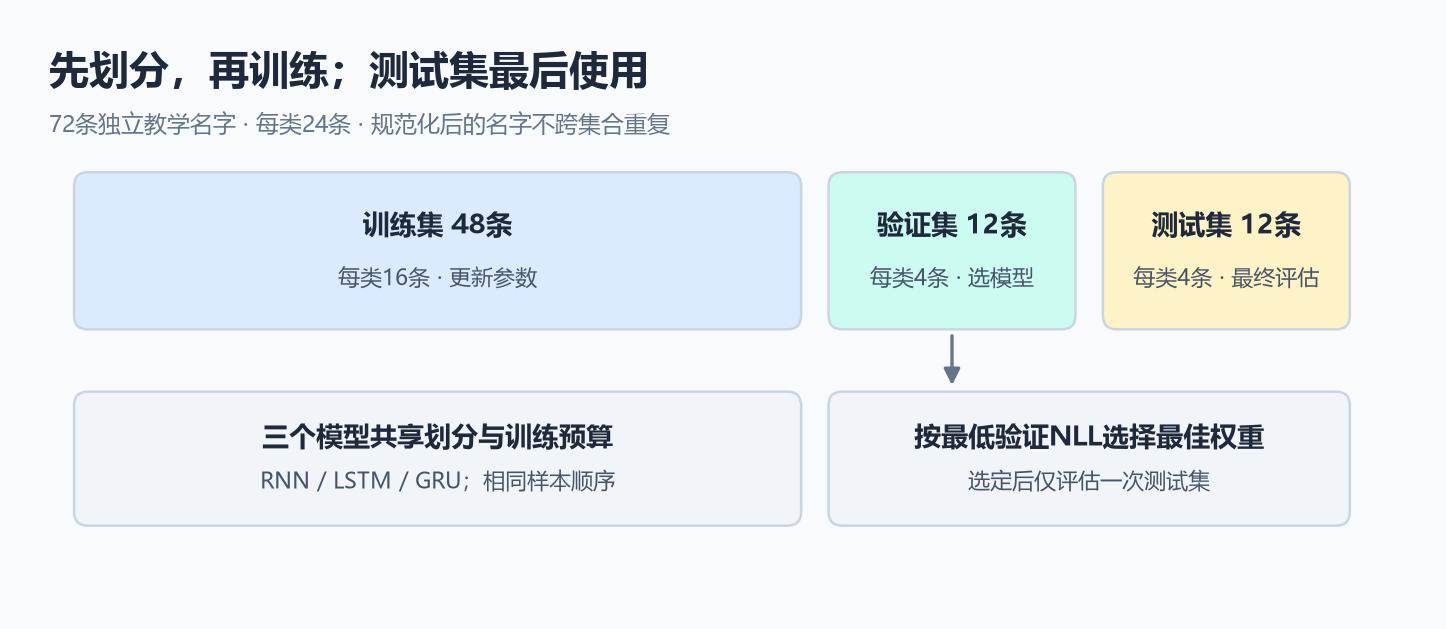

```python
split_rng = np.random.default_rng(SEED)
train_rows, dev_rows, test_rows = [], [], []
for category, names in TOY_NAMES.items():
    rows = [(normalize_name(n), CATEGORY_TO_ID[category]) for n in names]
    order = split_rng.permutation(len(rows)).tolist()
    train_rows.extend(rows[i] for i in order[:16])
    dev_rows.extend(rows[i] for i in order[16:20])
    test_rows.extend(rows[i] for i in order[20:])

split_sets = [set(n for n, _ in rows) for rows in (train_rows, dev_rows, test_rows)]
assert not (split_sets[0] & split_sets[1] or split_sets[0] & split_sets[2]
            or split_sets[1] & split_sets[2])
assert set.union(*split_sets) == {n for n, _ in all_rows}
assert [len(rows) for rows in (train_rows, dev_rows, test_rows)] == [48, 12, 12]
for label, rows in (("train", train_rows), ("dev", dev_rows), ("test", test_rows)):
    print(label, len(rows), {CATEGORIES[k]: v for k, v in Counter(y for _, y in rows).items()})
```

训练集用于更新参数；验证集用于选最佳轮次与模型；测试集只在选定模型后做一次最终评估。不能看测试表现反复改超参数，再把同一测试集称作独立评估。

## 14. Dataset、右padding和DataLoader

每个样本返回`(T,57)`与标量标签；collate返回`x/lengths/mask/labels`。mask用于核对，前向真正使用的是`lengths`和packing，不会仅因存在mask就自动忽略PAD。

```python
class NameDataset(Dataset):
    def __init__(self, rows):
        self.rows = list(rows)
        if not self.rows:
            raise ValueError("数据集不能为空")
        self.items = []
        for name, target in self.rows:
            if isinstance(target, bool) or not isinstance(target, int) or not 0 <= target < 18:
                raise ValueError("标签必须为0到17的整数")
            self.items.append((name_to_tensor(name), torch.tensor(target, dtype=torch.long)))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

def collate_names(items):
    if not items:
        raise ValueError("批次不能为空")
    sequences, labels = zip(*items)
    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
    x = pad_sequence(sequences, batch_first=True, padding_value=0.0)
    mask = torch.arange(x.shape[1])[None, :] < lengths[:, None]
    return x, lengths, mask, torch.stack(labels)

train_dataset = NameDataset(train_rows)
dev_dataset = NameDataset(dev_rows)
test_dataset = NameDataset(test_rows)

def make_loaders(seed=SEED, batch_size=16):
    generator = torch.Generator().manual_seed(seed)
    train = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                       generator=generator, collate_fn=collate_names, num_workers=0)
    dev = DataLoader(dev_dataset, batch_size=batch_size, shuffle=False,
                     collate_fn=collate_names, num_workers=0)
    return train, dev

example_x, example_lengths, example_mask, example_y = collate_names(
    [train_dataset[0], train_dataset[1], train_dataset[2]])
assert example_x.dtype == torch.float32 and example_y.dtype == torch.long
assert torch.equal(example_mask.sum(1), example_lengths)
assert torch.all(example_x[~example_mask] == 0)
assert torch.all(example_x[example_mask].sum(-1) == 1)
print("x", tuple(example_x.shape), "lengths", example_lengths.tolist(), "y", example_y.tolist())
```

比较三个模型时，每次新建同种子的DataLoader，使每轮样本顺序一致。为简化可复现性，本例`num_workers=0`；实际多进程和GPU训练还要配置相应随机数与确定性设置。

## 15. 一次训练更新到底做什么

流程：清空上一步梯度 → 前向 → 损失 → 反向传播 → 可选梯度裁剪 → 优化器更新。PyTorch默认累加梯度；如果忘记`zero_grad()`，下一次会叠加上一次结果。清零放在前向前或反向前都可以，但要在本轮`backward()`之前完成。

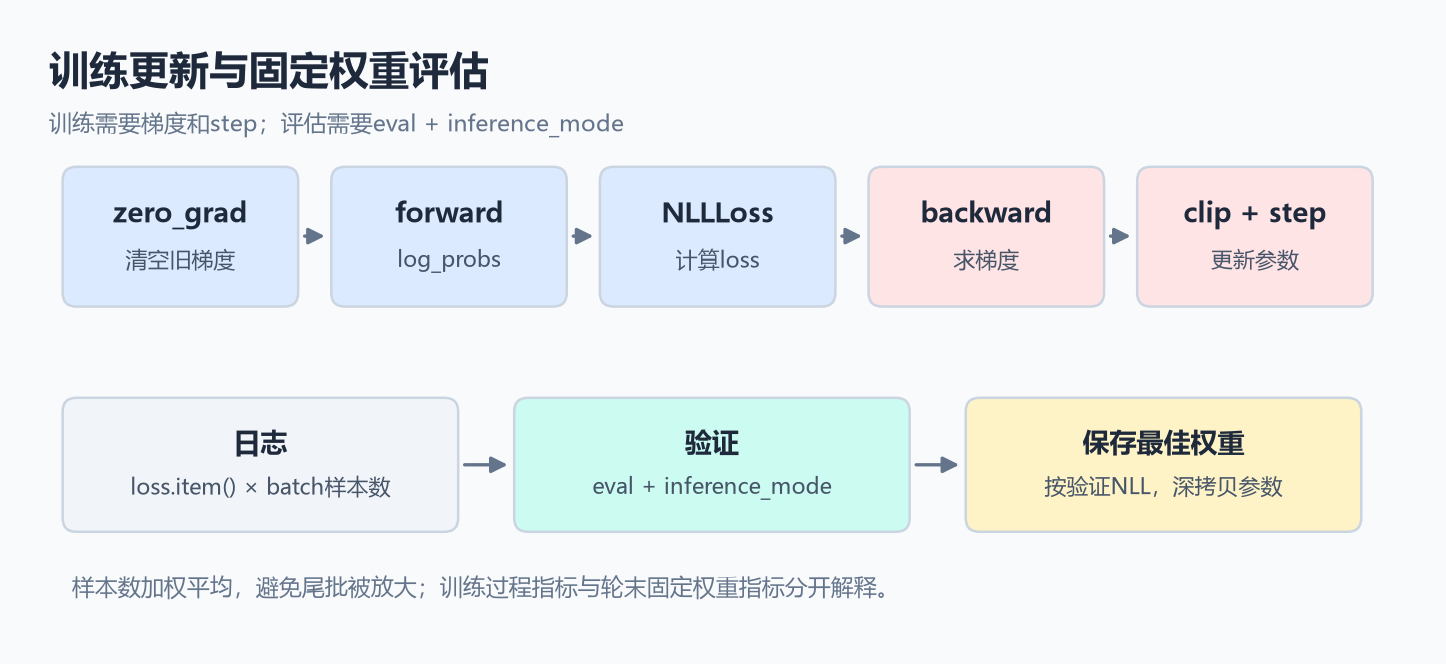

```python
torch.manual_seed(SEED)
update_probe = PackedNameClassifier("RNN", hidden_size=16).to(DEVICE)
optimizer_probe = torch.optim.Adam(update_probe.parameters(), lr=1e-2)
criterion = nn.NLLLoss()
before = update_probe.head.weight.detach().clone()
update_probe.train()
optimizer_probe.zero_grad(set_to_none=True)
lp = update_probe(example_x.to(DEVICE), example_lengths)
loss = criterion(lp, example_y.to(DEVICE))
assert torch.isfinite(loss)
loss.backward()
gradients = [p.grad for p in update_probe.parameters() if p.grad is not None]
assert gradients and all(torch.isfinite(g).all() for g in gradients)
norm_before_clip = nn.utils.clip_grad_norm_(update_probe.parameters(), max_norm=1.0)
optimizer_probe.step()
assert not torch.equal(before, update_probe.head.weight)
print("loss", loss.item(), "裁剪前梯度范数", norm_before_clip.item())
```

裁剪可以限制梯度范数，不能修复错误标签、数据泄漏、学习率问题或梯度消失。`loss.item()`用于日志，取出普通数值；反向传播仍使用原来的`loss`张量。

## 16. 正确统计一轮损失和准确率

平均损失必须按样本数加权：若默认`NLLLoss(reduction="mean")`返回批均值，则累加`loss.item() * batch_size`，最后除以总样本数。直接平均每批均值会让尾部小批次权重过大。类别预测用`argmax(dim=-1)`，不能对整个`(B,C)`张量做无维度argmax。

```python
def train_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for x, lengths, mask, labels in loader:
        x, labels = x.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        lp = model(x, lengths)
        loss = criterion(lp, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("训练损失非有限")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_size = labels.numel()
        loss_sum += loss.item() * batch_size
        correct += (lp.detach().argmax(-1) == labels).sum().item()
        count += batch_size
    if count == 0:
        raise ValueError("不能统计空迭代器")
    return {"loss": loss_sum / count, "accuracy": correct / count,
            "correct": correct, "count": count}

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for x, lengths, mask, labels in loader:
        x, labels = x.to(DEVICE), labels.to(DEVICE)
        lp = model(x, lengths)
        loss = criterion(lp, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("评估损失非有限")
        loss_sum += loss.item() * labels.numel()
        correct += (lp.argmax(-1) == labels).sum().item()
        count += labels.numel()
    if count == 0:
        raise ValueError("不能统计空迭代器")
    return {"loss": loss_sum / count, "accuracy": correct / count,
            "correct": correct, "count": count}
```

`train()/eval()`切换dropout等模块的行为；`no_grad()/inference_mode()`控制自动求导。**两者用途不同，eval不自动关闭梯度。** 本模型无dropout，仍遵循这套接口以方便以后扩展。

训练函数记录的是**本轮更新过程中的训练指标**：不同批次来自不同参数时刻；评估函数是某个固定权重在完整集合上的指标，两者不必完全相同。课件代码不断累计`total_loss/total_iter_num`，属于“从训练开始的累计均值”，不是“最近100步的均值”，也不是本篇逐轮均值。

## 17. 小检查：尾批计数与少量样本过拟合

先用批大小5评估12条验证样本，确认最后2条没有被漏掉，且加权平均与一次性整批计算一致。再让一个独立的GRU拟合4条训练样本，只检查训练流程是否能学习；不把这4条上的成绩当作泛化能力。

```python
tail_loader = DataLoader(dev_dataset, batch_size=5, collate_fn=collate_names)
full_loader = DataLoader(dev_dataset, batch_size=12, collate_fn=collate_names)
tail_metrics = evaluate(update_probe, tail_loader)
full_metrics = evaluate(update_probe, full_loader)
assert tail_metrics["count"] == 12
assert tail_metrics["correct"] == full_metrics["correct"]
assert abs(tail_metrics["loss"] - full_metrics["loss"]) < 1e-6

tiny_rows = []
for category, take in (("Chinese", 2), ("Russian", 1), ("English", 1)):
    tiny_rows.extend([row for row in train_rows if row[1] == CATEGORY_TO_ID[category]][:take])
assert all(row in train_rows for row in tiny_rows)
tiny_dataset = NameDataset(tiny_rows)
tiny_loader = DataLoader(tiny_dataset, batch_size=4, collate_fn=collate_names)
torch.manual_seed(SEED)
tiny_model = PackedNameClassifier("GRU", hidden_size=16).to(DEVICE)
tiny_optimizer = torch.optim.Adam(tiny_model.parameters(), lr=0.03)
tiny_before = evaluate(tiny_model, tiny_loader)
for _ in range(80):
    train_epoch(tiny_model, tiny_loader, tiny_optimizer)
tiny_after = evaluate(tiny_model, tiny_loader)
assert tiny_after["correct"] == 4 and tiny_after["loss"] < 0.1
assert tiny_after["loss"] < tiny_before["loss"]
print("尾批核对", tail_metrics["count"], "条；4条样本拟合:", tiny_before, "→", tiny_after)
```

这类检查能发现没有更新参数、状态串样本、标签或损失接口错误等问题。它不能替代独立验证集。

## 18. 统一训练预算，分别训练RNN、LSTM和GRU

每种模型使用相同划分、字符表、类别表、种子、样本顺序、隐藏维度、优化器、学习率、batch和35轮预算。按**验证NLL最低**保存每种模型的最佳轮次，再按同一标准选择最终模型；测试集尚不参与。

```python
KINDS = ("RNN", "LSTM", "GRU")
EPOCHS = 35
histories, trained_models, summaries = {}, {}, {}
for kind in KINDS:
    torch.manual_seed(SEED)
    train_loader, dev_loader = make_loaders()
    model = PackedNameClassifier(kind, hidden_size=32).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
    history = []
    best_loss, best_epoch, best_state = math.inf, None, None
    initial_train = evaluate(model, DataLoader(train_dataset, batch_size=16,
                                             collate_fn=collate_names))
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train_metrics = train_epoch(model, train_loader, optimizer)
        dev_metrics = evaluate(model, dev_loader)
        history.append({"epoch": epoch, "train_loss": train_metrics["loss"],
                        "train_acc": train_metrics["accuracy"],
                        "dev_loss": dev_metrics["loss"], "dev_acc": dev_metrics["accuracy"]})
        if dev_metrics["loss"] < best_loss:
            best_loss, best_epoch = dev_metrics["loss"], epoch
            best_state = copy.deepcopy(model.state_dict())
    elapsed = time.perf_counter() - started
    final_train = evaluate(model, DataLoader(train_dataset, batch_size=16,
                                           collate_fn=collate_names))
    assert final_train["loss"] < initial_train["loss"]
    assert best_state is not None
    model.load_state_dict(best_state)
    best_dev = evaluate(model, dev_loader)
    assert abs(best_dev["loss"] - best_loss) < 1e-7
    histories[kind] = history
    trained_models[kind] = model
    summaries[kind] = {"parameters": sum(p.numel() for p in model.parameters()),
                       "seconds": elapsed, "best_epoch": best_epoch,
                       "dev_loss": best_dev["loss"], "dev_acc": best_dev["accuracy"],
                       "dev_correct": best_dev["correct"], "dev_count": best_dev["count"],
                       "initial_train_loss": initial_train["loss"],
                       "final_train_loss": final_train["loss"],
                       "final_train_acc": final_train["accuracy"]}
    print(kind, summaries[kind])

selected_kind = min(KINDS, key=lambda k: summaries[k]["dev_loss"])
selected_model = trained_models[selected_kind]
print("按验证NLL选择:", selected_kind)
```

不同结构无法拥有完全相同的初始权重；这里固定种子和实验协议，也不保证每种结构都使用各自最佳超参数。可靠的比较应增加多次种子、更大的独立验证集和合理的调参预算。

耗时是这一次CPU运行的**训练、验证和最佳参数复制总墙钟时间**，不含建模、初始评估和最后评估；串行运行会受预热、后台负载影响。GPU计时另需同步，这个数字不是纯推理速度或通用性能排名。

## 19. 读取本篇真实训练曲线

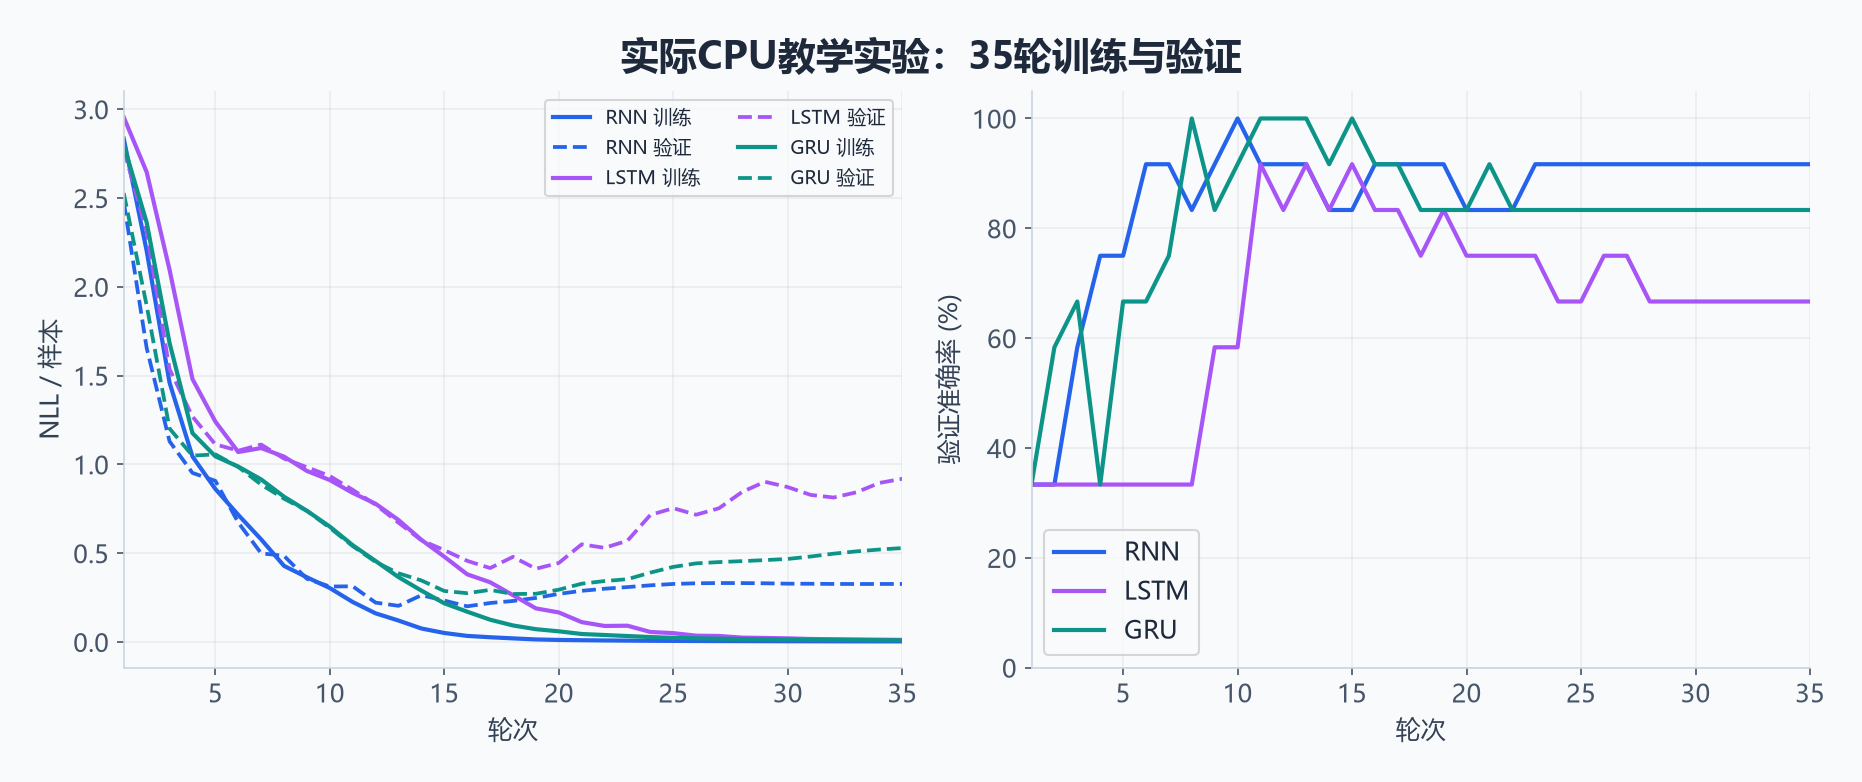

上图来自前一节实际执行的`histories`，不是课件原图。横轴是轮次；左图实线为本轮训练NLL、虚线为轮末验证NLL；右图为验证准确率。只有12条验证样本，准确率以`1/12≈8.33%`为步长变化。

- 训练损失下降、验证损失也下降：至少在当前划分上学习有益。
- 训练损失继续下降、验证损失反而上升：可能在记忆训练样本；结合多次种子、类别指标与更多验证数据判断。
- 准确率相同但NLL不同：预测对错相同，分配给真实类别的概率不同。错误且过于自信会被NLL明显惩罚。

本篇按最低验证NLL选轮次，因此“最后一轮”不一定是保存模型。选到最早或最晚一轮也不自动证明训练预算充足，仍要观察曲线。

## 20. 三种模型比较：本篇结果与课件结论

| 模型 | 参数量 | 35轮用时/秒 | 最佳轮次 | 验证NLL | 验证正确数 | 最后一轮训练准确率 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| RNN | 3506 | 0.408 | 16 | 0.2005 | 11/12 | 100.00% |
| LSTM | 12242 | 0.560 | 19 | 0.4121 | 10/12 | 100.00% |
| GRU | 9330 | 0.601 | 18 | 0.2698 | 10/12 | 100.00% |

按预先定义的验证NLL标准，本次选定 **RNN**。

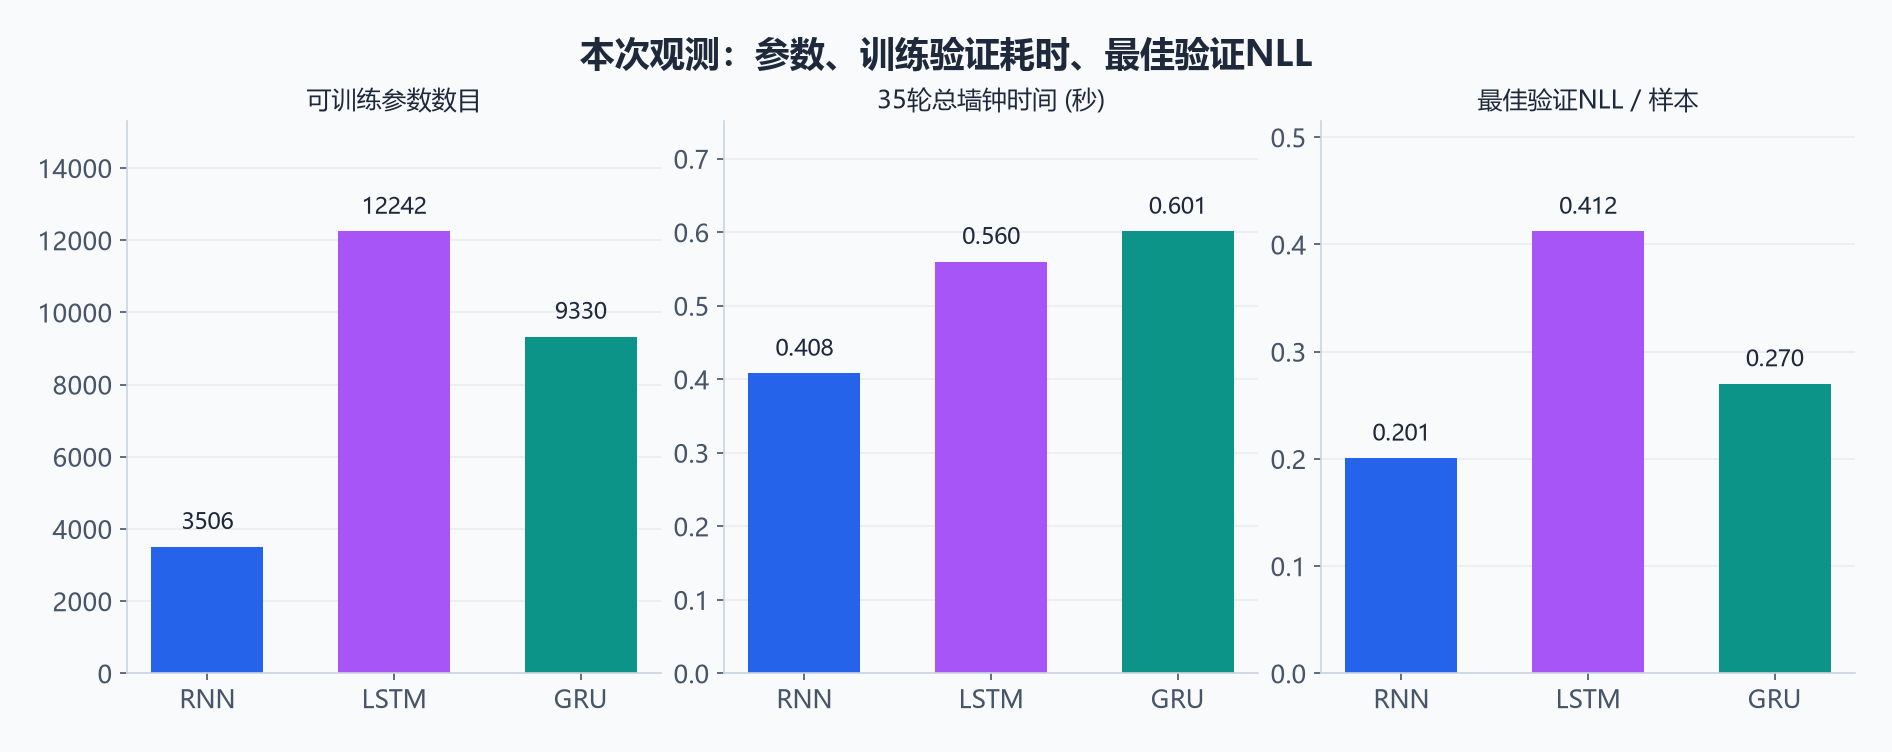

上表与图是**本次CPU、72条教学样本的观测**。验证结果对应各模型的最佳验证NLL轮次；训练指标对应最后一轮的固定权重，两个时刻不能混为一谈。表中耗时口径见第18节。

课件第36–40页在它的实验中观察到：RNN初期收敛较快、用时较短，后续GRU训练准确率较高，综合选择GRU。这里记录为**课程特定实验观察**，未复现其数据、代码、硬件和训练过程。不能推广成“任何任务GRU最好”“RNN一定快一倍”。

选择模型应依据任务的验证指标、运行成本和误差类型。真实18类不均衡数据还应报告每类召回、宏平均F1、混淆矩阵；只看总体准确率可能掩盖少数类问题。

## 21. 选定模型后，仅一次测试评估

下面只评估按验证NLL选定的模型，不用测试成绩在三种模型之间重新挑选。测试是12条独立教学样本，规模太小，不报告有统计意义的普遍排名。

```python
test_loader = DataLoader(test_dataset, batch_size=5, shuffle=False,
                         collate_fn=collate_names, num_workers=0)
test_metrics = evaluate(selected_model, test_loader)
assert test_metrics["count"] == 12
print("选定模型", selected_kind, "测试结果", test_metrics)

@torch.inference_mode()
def collect_predictions(model, loader):
    model.eval()
    truths, predictions = [], []
    for x, lengths, mask, labels in loader:
        pred = model(x.to(DEVICE), lengths).argmax(-1).cpu()
        truths.extend(labels.tolist())
        predictions.extend(pred.tolist())
    return truths, predictions

test_truth, test_pred = collect_predictions(selected_model, test_loader)
confusion = torch.zeros((18, 18), dtype=torch.long)
for truth, pred in zip(test_truth, test_pred):
    confusion[truth, pred] += 1
assert confusion.sum().item() == 12
assert confusion.diag().sum().item() == test_metrics["correct"]
for category in TOY_NAMES:
    idx = CATEGORY_TO_ID[category]
    total = confusion[idx].sum().item()
    print(category, "召回", confusion[idx, idx].item(), "/", total)
print("行=真实、列=预测；非零项:", [(CATEGORIES[a], CATEGORIES[b], int(confusion[a, b]))
                                     for a, b in confusion.nonzero().tolist()])
```

本次选定 **RNN**，一次测试评估NLL为 **0.2573**，正确 **11/12**（91.67%）。

每类测试只有4条，单个错误改变该类召回率25个百分点。此结果仅用于教学流程核验，不是课程原实验或实际应用性能承诺。

## 22. 预测接口：输入检查、eval与Top-k

`topk`在类别轴排序，返回分数与索引；索引必须通过训练时的同一`CATEGORIES`映射回标签。对数概率与概率排序一致，可以先对log_probs取Top-k，再指数化显示。

```python
@torch.inference_mode()
def predict_name(model, name, k=3):
    if isinstance(k, bool) or not isinstance(k, int) or not 1 <= k <= len(CATEGORIES):
        raise ValueError("k必须为1到18的整数")
    normalized = normalize_name(name)
    sequence = name_to_tensor(normalized)
    x = sequence.unsqueeze(0).to(next(model.parameters()).device)
    lengths = torch.tensor([len(sequence)], dtype=torch.long)
    model.eval()
    lp = model(x, lengths)
    assert lp.shape == (1, 18)
    assert torch.isfinite(lp).all()
    torch.testing.assert_close(lp.exp().sum(-1), torch.ones(1, device=lp.device))
    values, indices = lp.topk(k, dim=-1)
    predictions = [{"category": CATEGORIES[idx], "log_probability": float(value),
                    "probability": math.exp(float(value))}
                   for value, idx in zip(values[0].cpu().tolist(), indices[0].cpu().tolist())]
    return {"input": name, "normalized": normalized, "topk": predictions}

demo_predictions = {}
for kind in KINDS:
    demo_predictions[kind] = predict_name(trained_models[kind], "Zhang", k=3)
    print(kind, demo_predictions[kind])
assert predict_name(selected_model, "  José  ")["normalized"] == "Jose"
for invalid_k in (0, 19, True):
    try:
        predict_name(selected_model, "Zhang", invalid_k)
    except ValueError:
        pass
    else:
        raise AssertionError("应拒绝错误k")
```

Top-3概率和通常**小于1**，不要再把这三项归一化并称为原18类概率。Softmax分数也不天然校准；例如`0.9`不保证90%同类预测正确。未知类别、未覆盖拼写或陌生语言仍会被强制分到18类之一，需要另设计拒识策略与评估。

课件以`zhang`举例。本篇保留大小写，因此`zhang`和`Zhang`是不同输入；其预测不能与课件直接对比。以上示例未用于选模型或调参。

## 23. 保存参数时，也保存“参数的解释方式”

只有`state_dict`不够：输入维度、隐藏维度、层数、类别顺序、字符顺序、大小写策略一旦改变，同一组参数可能无法加载，或悄悄对应错误标签。训练与推理必须共享完整契约。

建议checkpoint包含：

- `state_dict`：参数与持久buffer。
- `model_config`：结构类型、输入/隐藏/输出维度和层数。
- `alphabet/categories/preprocess`：编码和标签解释规则。
- `selection`：按哪种验证指标选定、最佳轮次与验证损失。

继续训练还需保存优化器状态、训练轮次、随机数状态等；本篇只演示**推理checkpoint**。不推荐直接序列化整个模型实例来替代清晰的结构与参数契约。

```python
def create_checkpoint(model, summary):
    return {
        "format_version": 1,
        "model_config": dict(model.config),
        "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
        "alphabet": ALL_LETTERS,
        "categories": list(CATEGORIES),
        "preprocess": PREPROCESS,
        "selection": {"metric": "dev_nll_min", "epoch": summary["best_epoch"],
                      "value": summary["dev_loss"]},
        "dataset": "independent_toy_72_names_3_observed_labels",
    }

checkpoint = create_checkpoint(selected_model, summaries[selected_kind])
assert checkpoint["model_config"]["num_classes"] == len(checkpoint["categories"])
assert all(value.device.type == "cpu" for value in checkpoint["state_dict"].values())
print("checkpoint:", {k: v for k, v in checkpoint.items() if k != "state_dict"})
```

## 24. 加载后必须核对输出一致

用本篇刚生成的文件示范`torch.load(..., map_location="cpu", weights_only=True)`。验证配置后重建结构，再`load_state_dict(strict=True)`；`eval()`和关闭梯度都要做。仅“加载没有报错”不能保证标签映射正确。

```python
def restore_model(checkpoint):
    if checkpoint["format_version"] != 1:
        raise ValueError("不支持的checkpoint版本")
    if checkpoint["alphabet"] != ALL_LETTERS or checkpoint["categories"] != CATEGORIES:
        raise ValueError("字符或类别顺序不一致")
    if checkpoint["preprocess"] != PREPROCESS:
        raise ValueError("预处理规则不一致")
    config = checkpoint["model_config"]
    if config["input_size"] != len(ALL_LETTERS) or config["num_classes"] != len(CATEGORIES):
        raise ValueError("模型维度与编码契约不一致")
    model = PackedNameClassifier(**config).to(DEVICE)
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    return model.eval()

with tempfile.TemporaryDirectory(prefix="nlp_day04_") as temp_dir:
    saved_path = Path(temp_dir) / "name_classifier.pt"
    torch.save(checkpoint, saved_path)
    loaded_checkpoint = torch.load(saved_path, map_location="cpu", weights_only=True)
    restored_model = restore_model(loaded_checkpoint)
    with torch.inference_mode():
        x, lengths, _, _ = next(iter(full_loader))
        expected = selected_model(x.to(DEVICE), lengths)
        actual = restored_model(x.to(DEVICE), lengths)
        torch.testing.assert_close(expected, actual, atol=0, rtol=0)
    restored_prediction = predict_name(restored_model, "Zhang")
    assert restored_prediction == predict_name(selected_model, "Zhang")
    print("保存/加载最大误差:", (expected - actual).abs().max().item())
    print("加载后预测:", restored_prediction)

wrong_mapping = dict(checkpoint, categories=list(reversed(CATEGORIES)))
try:
    restore_model(wrong_mapping)
except ValueError:
    print("已拒绝类别顺序不一致的配置")
else:
    raise AssertionError("类别顺序错误不应通过")
```

`weights_only=True`用于本例的张量与基础类型checkpoint，不能把任意来源文件当作已验证文件。课件预测代码有`my_rnn/myrnn`等命名混用；本篇统一变量和模型配置，避免加载到了错误对象。

## 25. 常见问题速查

| 现象 | 常见原因 | 检查与修正 |
| --- | --- | --- |
| 输出是负数，以为概率错了 | LogSoftmax输出对数概率 | `.exp()`，核对每行和为1 |
| loss不下降 | 未step、标签错位、梯度没清、学习率不合适 | 先检查4条样本能否拟合 |
| loss为NaN/Inf | 不稳定指数、异常输入、更新过大 | 稳定损失、finite检查、检查梯度与学习率 |
| 不同batch结果不同 | 取到PAD末尾或跨名字复用hidden | packing+真实lengths；每次从零状态开始 |
| `Expected target Long` | 标签dtype错误 | 类别索引使用long `(B,)` |
| batch中的预测只剩一个数字 | 全局argmax | `(B,C).argmax(dim=-1)` |
| LSTM提示hidden类型错误 | 漏掉细胞状态c | 传`(h0,c0)`、返回`(hn,cn)` |
| 加载成功但类别完全不对 | 类别表或字符表顺序改变 | 配置随参数一起保存并校验 |
| 训练100%、验证明显差 | 小样本记忆或数据偏差 | 独立验证、增加数据、分析错误类别 |
| 平均loss因batch改变而变化大 | 平均批均值、漏尾批 | 按真实样本数加权，核对count |

日志累加`total_loss += loss`会把张量和计算图引用带到统计变量中；通常应累加`loss.item()`。最佳参数快照使用`deepcopy(model.state_dict())`或克隆张量，避免后续训练继续覆盖同一引用。

## 26. 练习与参考答案

1. 输出shape为`(16,18)`，标签应是什么shape和dtype？  
   **答：** `(16,)`、long，每个值在`0…17`。

2. 名字长度为`[2,6,4]`，右补齐到6，怎样取每个最终状态？  
   **答：** 传入CPU lengths，pack后取单向顶层`hn[-1]`；不能全部取第6位置。

3. 训练完调用`model.eval()`，是否就不会记录梯度？  
   **答：** 不会自动关闭。评估/预测还要`no_grad()`或`inference_mode()`。

4. 三个批次分别有5、5、2个样本，批均值为1、2、3，整轮均值是多少？  
   **答：** `(5*1+5*2+2*3)/12=1.75`，不是2。

5. Top-3概率为0.4、0.2、0.1，剩余类别概率是多少？  
   **答：** 共0.3；三个结果不应强行重新归一化解释成18类概率。

6. 训练成绩GRU最高，为什么不能直接认定GRU最适合新数据？  
   **答：** 训练集允许记忆；要按独立验证、多次种子、成本和误差类型选择，再做最终测试。

7. 同一参数文件，类别顺序倒过来会怎样？  
   **答：** 输出列的数值可能完全不变，解释标签却全部错位；保存和加载时核对顺序。

8. 若想训练真实18类数据，第一步是什么？  
   **答：** 获取并核验原始TSV和标签定义，审查规范化重复与未知字符，再建立无泄漏划分。不能直接把本篇72条数据的结果扩展成18类结论。

## 27. 本篇核验记录

本文件所有 **20段Python代码**已按顺序在CPU执行，环境为Python 3.12.13、NumPy 1.26.4、PyTorch 2.14.1+cpu。

已检查：LogSoftmax稳定性及概率和；NLL与CE数值和梯度一致；字符与类别顺序；未知输入拒绝；三种模型整段/逐字符一致；packed/逐条一致及额外PAD无关性；参数量公式；划分无重复；梯度有限且参数更新；尾批计数；4条样本拟合；三模型35轮真实训练；最佳权重恢复；选定后一次测试；Top-k和保存加载输出一致。

- 保存加载后同批输出最大误差：`0.0`。
- 数据划分：训练48 / 验证12 / 测试12，18个输出类别中3类有正样本。
- 自绘教学图：7幅，全部使用Notebook内嵌附件。
- 三模型实验数据、选定模型及本次结果保存在Notebook metadata中，便于复查。

上述检查验证了教学代码的接口与计算流程。它们不表示已复现课程原始实验；本篇没有原始人名数据，也未将视频逐段转录。

## 28. 资料索引与下一步

资料：[NLP自然语言处理共享目录](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。

| 来源 | 已核对范围 | 本篇使用 |
| --- | --- | --- |
| `03-视频/day04` | 全部11节文件名 | 确认当天内容与顺序；未转录视频 |
| `01-课件/05-RNN案例人名分类器.pdf` | 在线阅读1–47页 | 18–25模型；28–33训练；34–40图与结论；42–47预测 |
| 第03篇 | 数据规范、one-hot、collate、packed接口 | 本篇独立重写必要接口以便连续运行 |
| [PyTorch RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html) | 扩展阅读 | 输入、输出与隐藏状态说明 |
| [PyTorch NLLLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.NLLLoss.html) | 扩展阅读 | 对数概率输入与类别索引 |
| [pack_padded_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html) | 扩展阅读 | 长度、排序、packed序列 |
| [保存与加载模型](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) | 扩展阅读 | state_dict与推理模式 |

本篇把“数据准备”接成了完整分类实验：先核对形状与状态，再训练、验证、选择、测试，最后保存契约并预测。下一篇的具体主题以day05目录为准，不提前把其他任务混入本日案例。